In [4]:
# ==========================================
# CELL 1: Verify GPU & Libraries
# ==========================================
import torch
import optuna

print("=" * 45)
print(f"PyTorch Version:  {torch.__version__}")
print(f"CUDA Available:   {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Active GPU:       {torch.cuda.get_device_name(0)}")
    print(f"Dedicated VRAM:   {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    print("STATUS: SUCCESS! Connected to NVIDIA GeForce MX330 GPU.")
else:
    print("STATUS: GPU not detected.")
print("=" * 45)

PyTorch Version:  2.14.0+cu126
CUDA Available:   True
Active GPU:       NVIDIA GeForce MX330
Dedicated VRAM:   2.00 GB
STATUS: SUCCESS! Connected to NVIDIA GeForce MX330 GPU.


In [5]:
# =======================================================
# CELL 2: Imports, Seeds, Device & Path Verification
# =======================================================
import os
import random
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

# 1. Reproducibility
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(SEED)

# 2. Hardware Device Setup (MX330 - 2GB VRAM)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active compute device: {DEVICE}")

# 3. Path Setup (Relative to current folder)
DATA_DIR = Path(".")
FILES = {
    "train": DATA_DIR / "sequences_train.npz",
    "val": DATA_DIR / "sequences_validation.npz",
    "test": DATA_DIR / "sequences_test.npz",
    "scaler": DATA_DIR / "target_sales_scaler.joblib",
    "report": DATA_DIR / "sequence_generation_multivariate_report.json"
}

# 4. Verify all files exist in this folder
print("\nVerifying sequence artifacts:")
all_exist = True
for name, path in FILES.items():
    exists = path.exists()
    status = "FOUND" if exists else "MISSING"
    size_mb = f"({path.stat().st_size / (1024**2):.1f} MB)" if exists else ""
    print(f"  - [{status}] {name:8s} -> {path.name} {size_mb}")
    if not exists:
        all_exist = False

if all_exist:
    print("\nSTATUS: All data files confirmed present and ready!")
else:
    print("\nWARNING: Some files were not found. Please verify the folder.")

Active compute device: cuda

Verifying sequence artifacts:
  - [FOUND] train    -> sequences_train.npz (1924.7 MB)
  - [FOUND] val      -> sequences_validation.npz (10.2 MB)
  - [FOUND] test     -> sequences_test.npz (10.0 MB)
  - [FOUND] scaler   -> target_sales_scaler.joblib (0.0 MB)
  - [FOUND] report   -> sequence_generation_multivariate_report.json (0.0 MB)

STATUS: All data files confirmed present and ready!


In [6]:
# =====================================================================
# CELL 3: Dataset Class, Static Categorical Encodings & DataLoaders
# =====================================================================
import time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

t0 = time.time()
print("1. Loading sequence data via memory-mapping...")
train_npz = np.load(FILES["train"], mmap_mode="r")
val_npz   = np.load(FILES["val"],   mmap_mode="r")
test_npz  = np.load(FILES["test"],  mmap_mode="r")

static_cols = [
    "store_nbr", "item_nbr", "family", "class",
    "perishable", "city", "state", "type", "cluster"
]

# 2. Build category mappings strictly from training data
print("2. Computing category cardinalities from training data...")
cat_categories = {}
cat_cardinalities = []

for col in static_cols:
    uniques = np.unique(train_npz[col])
    cat_categories[col] = uniques
    cat_cardinalities.append(len(uniques))
    print(f"   - {col:12s}: {len(uniques):3d} unique categories")

# 3. Memory-efficient TFT Dataset
class TFTDataset(Dataset):
    def __init__(self, npz_data, cat_categories, static_cols):
        self.past_x = npz_data["past_x"]      # (N, 28, 18)
        self.future_x = npz_data["future_x"]  # (N, 7, 14)
        self.y = npz_data["y"]                # (N, 7)
        self.y_raw = npz_data["y_raw"]        # (N, 7)
        self.n_samples = len(self.y)

        # Pre-convert static columns into integer tensor matrix (N, 9)
        static_matrix = np.column_stack([
            pd.Categorical(npz_data[col], categories=cat_categories[col]).codes.astype(np.int64)
            for col in static_cols
        ])
        # Replace any unseen categories (marked as -1) with 0
        static_matrix = np.clip(static_matrix, a_min=0, a_max=None)
        self.static_x = torch.tensor(static_matrix, dtype=torch.long)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        return {
            "past_x":   torch.tensor(self.past_x[idx],   dtype=torch.float32),
            "future_x": torch.tensor(self.future_x[idx], dtype=torch.float32),
            "static_x": self.static_x[idx],
            "y":        torch.tensor(self.y[idx],        dtype=torch.float32),
            "y_raw":    torch.tensor(self.y_raw[idx],    dtype=torch.float32)
        }

print("\n3. Initializing Train, Validation, and Test Datasets...")
train_dataset = TFTDataset(train_npz, cat_categories, static_cols)
val_dataset   = TFTDataset(val_npz,   cat_categories, static_cols)
test_dataset  = TFTDataset(test_npz,  cat_categories, static_cols)

# 4. DataLoaders (batch_size=128 is memory-safe for 2GB MX330)
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

# 5. Sanity check shapes on a single batch
sample_batch = next(iter(train_loader))
print(f"\n4. Batch verification completed in {time.time() - t0:.2f}s:")
print(f"   - past_x shape:   {tuple(sample_batch['past_x'].shape)}   (Expected: [128, 28, 18])")
print(f"   - future_x shape: {tuple(sample_batch['future_x'].shape)}   (Expected: [128, 7, 14])")
print(f"   - static_x shape: {tuple(sample_batch['static_x'].shape)}   (Expected: [128, 9])")
print(f"   - y shape:        {tuple(sample_batch['y'].shape)}   (Expected: [128, 7])")
print(f"   - y_raw shape:    {tuple(sample_batch['y_raw'].shape)}   (Expected: [128, 7])")
print("STATUS: DataLoaders initialized successfully!")

1. Loading sequence data via memory-mapping...
2. Computing category cardinalities from training data...
   - store_nbr   :  53 unique categories
   - item_nbr    : 122 unique categories
   - family      :  32 unique categories
   - class       :  65 unique categories
   - perishable  :   2 unique categories
   - city        :  22 unique categories
   - state       :  16 unique categories
   - type        :   5 unique categories
   - cluster     :  17 unique categories

3. Initializing Train, Validation, and Test Datasets...

4. Batch verification completed in 20.47s:
   - past_x shape:   (128, 28, 18)   (Expected: [128, 28, 18])
   - future_x shape: (128, 7, 14)   (Expected: [128, 7, 14])
   - static_x shape: (128, 9)   (Expected: [128, 9])
   - y shape:        (128, 7)   (Expected: [128, 7])
   - y_raw shape:    (128, 7)   (Expected: [128, 7])
STATUS: DataLoaders initialized successfully!


In [7]:
# =====================================================================
# CELL 4: Import and Validate TFT Architecture
# =====================================================================
import torch
from tft_model import TemporalFusionTransformer

# 1. Instantiate TFT Model
test_model = TemporalFusionTransformer(
    static_cardinalities=cat_cardinalities,
    hidden_size=64,
    embedding_size=16,
    num_heads=4,
    dropout=0.1
).to(DEVICE)

# 2. Test single forward pass using the sample batch from Cell 3
with torch.no_grad():
    b_past   = sample_batch["past_x"].to(DEVICE)
    b_future = sample_batch["future_x"].to(DEVICE)
    b_static = sample_batch["static_x"].to(DEVICE)
    b_out    = test_model(b_past, b_future, b_static)

params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print("=" * 45)
print(f"Device:               {DEVICE}")
print(f"Trainable Parameters: {params:,}")
print(f"Forward Pass Output:  {tuple(b_out.shape)}  (Expected: [128, 7])")
print(f"Contains NaNs:        {torch.isnan(b_out).any().item()}")
print("STATUS: TFT Architecture validated successfully!")
print("=" * 45)

Device:               cuda
Trainable Parameters: 807,959
Forward Pass Output:  (128, 7)  (Expected: [128, 7])
Contains NaNs:        False
STATUS: TFT Architecture validated successfully!


In [8]:
# =====================================================================
# CELL 5: Loss Function, Inverse Scaler & Evaluation Metrics (WAPE)
# =====================================================================
import joblib
import numpy as np
import torch
import torch.nn as nn

# 1. Training Loss Function (Huber Loss / Smooth L1)
criterion = nn.HuberLoss(delta=1.0)

# 2. Load the fitted training scaler artifact
scaler_artifact = joblib.load(FILES["scaler"])
target_scaler = scaler_artifact["target_scaler"]

# 3. Inverse Scaling Function (from scaled log space back to real sales units)
def inverse_scale(predictions, scaler):
    if isinstance(predictions, torch.Tensor):
        preds_np = predictions.detach().cpu().numpy()
    else:
        preds_np = np.asarray(predictions)
    
    orig_shape = preds_np.shape
    flattened = preds_np.reshape(-1, 1)
    unscaled_log = scaler.inverse_transform(flattened)
    raw_sales = np.expm1(unscaled_log).reshape(orig_shape)
    return np.clip(raw_sales, a_min=0.0, a_max=None)

# 4. Metric Computation Function
def compute_metrics(y_true_raw, y_pred_raw):
    # Both inputs are 2D numpy arrays of shape (N, 7)
    abs_errors = np.abs(y_true_raw - y_pred_raw)
    mae = np.mean(abs_errors)
    rmse = np.sqrt(np.mean((y_true_raw - y_pred_raw) ** 2))
    
    total_actual = np.sum(y_true_raw)
    total_abs_error = np.sum(abs_errors)
    wape = (total_abs_error / total_actual) * 100.0 if total_actual > 0 else 0.0
    
    return {
        "MAE": round(float(mae), 4),
        "RMSE": round(float(rmse), 4),
        "WAPE (%)": round(float(wape), 2)
    }

# 5. Sanity Test on the sample batch from Cell 4
y_true_raw_sample = sample_batch["y_raw"].numpy()
y_pred_raw_sample = inverse_scale(b_out, target_scaler)
sample_metrics = compute_metrics(y_true_raw_sample, y_pred_raw_sample)

print("=" * 45)
print("Loss Function:        nn.HuberLoss(delta=1.0)")
print(f"Inverse Scaled Shape: {y_pred_raw_sample.shape}  (Expected: (128, 7))")
print(f"Sample Batch MAE:     {sample_metrics['MAE']}")
print(f"Sample Batch RMSE:    {sample_metrics['RMSE']}")
print(f"Sample Batch WAPE:    {sample_metrics['WAPE (%)']}%")
print("STATUS: Loss and Metric functions verified successfully!")
print("=" * 45)

Loss Function:        nn.HuberLoss(delta=1.0)
Inverse Scaled Shape: (128, 7)  (Expected: (128, 7))
Sample Batch MAE:     35.8462
Sample Batch RMSE:    69.928
Sample Batch WAPE:    77.29%
STATUS: Loss and Metric functions verified successfully!


In [9]:
# =====================================================================
# CELL 6: Training Step & Validation Evaluation Functions
# =====================================================================
import time
import torch
import numpy as np

# 1. Train for One Epoch
def train_epoch(model, dataloader, optimizer, criterion, device, max_batches=None):
    model.train()
    running_loss = 0.0
    batches_run = 0

    for batch in dataloader:
        past_x   = batch["past_x"].to(device)
        future_x = batch["future_x"].to(device)
        static_x = batch["static_x"].to(device)
        targets  = batch["y"].to(device)

        optimizer.zero_grad()
        predictions = model(past_x, future_x, static_x)
        loss = criterion(predictions, targets)
        loss.backward()

        # Gradient clipping prevents exploding gradients in recurrent/attention layers
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()
        batches_run += 1

        if max_batches is not None and batches_run >= max_batches:
            break

    return running_loss / batches_run

# 2. Evaluate on Validation / Test Set
def evaluate(model, dataloader, criterion, scaler, device):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_trues_raw = []

    with torch.no_grad():
        for batch in dataloader:
            past_x   = batch["past_x"].to(device)
            future_x = batch["future_x"].to(device)
            static_x = batch["static_x"].to(device)
            targets  = batch["y"].to(device)

            preds = model(past_x, future_x, static_x)
            loss = criterion(preds, targets)
            total_loss += loss.item()

            all_preds.append(preds.cpu())
            all_trues_raw.append(batch["y_raw"])

    avg_loss = total_loss / len(dataloader)
    
    # Concatenate and invert scaling to compute real-world sales metrics
    concat_preds = torch.cat(all_preds, dim=0).numpy()
    concat_trues = torch.cat(all_trues_raw, dim=0).numpy()
    raw_preds = inverse_scale(concat_preds, scaler)
    metrics = compute_metrics(concat_trues, raw_preds)
    metrics["Loss"] = round(avg_loss, 4)
    
    return metrics

# 3. Dry-Run Verification (Test 1 batch of training + validation evaluation)
print("Running dry-run test on model and GPU...")
dry_opt = torch.optim.AdamW(test_model.parameters(), lr=1e-3)

t0 = time.time()
dry_train_loss = train_epoch(test_model, train_loader, dry_opt, criterion, DEVICE, max_batches=2)
dry_val_metrics = evaluate(test_model, val_loader, criterion, target_scaler, DEVICE)

print("=" * 45)
print(f"Dry-Run Completed in: {time.time() - t0:.2f}s")
print(f"Train Step Loss:      {dry_train_loss:.4f}")
print(f"Validation Loss:      {dry_val_metrics['Loss']}")
print(f"Validation MAE:       {dry_val_metrics['MAE']}")
print(f"Validation WAPE:      {dry_val_metrics['WAPE (%)']}%")
print("STATUS: Training & Evaluation loops verified successfully!")
print("=" * 45)

Running dry-run test on model and GPU...
Dry-Run Completed in: 6.83s
Train Step Loss:      0.5261
Validation Loss:      0.4037
Validation MAE:       33.614
Validation WAPE:      78.73%
STATUS: Training & Evaluation loops verified successfully!


In [10]:
# =====================================================================
# CELL 7: Optuna Objective Function & Hyperparameter Optimization Study
# =====================================================================
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

# Suppress verbose Optuna trial logs to keep notebook output clean
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Define the Optuna Objective Function
def objective(trial):
    # A. Suggest Hyperparameters
    lr           = trial.suggest_float("lr", 1e-4, 5e-3, log=True)
    hidden_size  = trial.suggest_categorical("hidden_size", [32, 64])
    num_heads    = trial.suggest_categorical("num_heads", [2, 4])
    dropout      = trial.suggest_float("dropout", 0.05, 0.25, step=0.05)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    # B. Instantiate TFT Model with the suggested architecture
    model = TemporalFusionTransformer(
        static_cardinalities=cat_cardinalities,
        hidden_size=hidden_size,
        embedding_size=16,
        num_heads=num_heads,
        dropout=dropout,
        forecast_horizon=7
    ).to(DEVICE)

    # C. Optimizer & Loss
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    # D. Train for 3 screening epochs (with 250 batches per epoch for fast HPO screening)
    best_trial_wape = float("inf")
    EPOCHS_PER_TRIAL = 3
    MAX_BATCHES = 250

    for epoch in range(1, EPOCHS_PER_TRIAL + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, DEVICE, max_batches=MAX_BATCHES)
        val_metrics = evaluate(model, val_loader, criterion, target_scaler, DEVICE)
        val_wape = val_metrics["WAPE (%)"]

        if val_wape < best_trial_wape:
            best_trial_wape = val_wape

        # Report metric to Optuna for pruning decision
        trial.report(val_wape, epoch)

        # Early Pruning: Terminate trial if it's lagging behind earlier trials
        if trial.should_prune():
            del model, optimizer
            torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

    # Free GPU memory before next trial
    del model, optimizer
    torch.cuda.empty_cache()
    return best_trial_wape

# 2. Configure Optuna Study (Bayesian TPE Sampler + Median Pruner)
SEED = 42
sampler = TPESampler(seed=SEED)
pruner  = MedianPruner(n_startup_trials=2, n_warmup_steps=1)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    pruner=pruner,
    study_name="TFT_Demand_Forecasting"
)

# 3. Run Optimization
N_TRIALS = 5
print("=" * 55)
print(f"Starting Optuna Optimization ({N_TRIALS} Trials)...")
print("Minimizing: Validation WAPE (%) on NVIDIA MX330 GPU")
print("=" * 55)

study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

# 4. Display Champion Results
print("\n" + "=" * 55)
print("OPTUNA OPTIMIZATION COMPLETED!")
print(f"Best Trial Number:     #{study.best_trial.number}")
print(f"Best Validation WAPE:  {study.best_value:.2f}%")
print("Best Hyperparameters:")
for param_name, param_value in study.best_params.items():
    print(f"  - {param_name:15s}: {param_value}")
print("=" * 55)

Starting Optuna Optimization (5 Trials)...
Minimizing: Validation WAPE (%) on NVIDIA MX330 GPU


  0%|          | 0/5 [00:00<?, ?it/s]


OPTUNA OPTIMIZATION COMPLETED!
Best Trial Number:     #1
Best Validation WAPE:  31.97%
Best Hyperparameters:
  - lr             : 0.0029621516588303515
  - hidden_size    : 64
  - num_heads      : 4
  - dropout        : 0.25
  - weight_decay   : 2.6587543983272695e-05


In [12]:
# =====================================================================
# CELL 8: Train Champion TFT with Early Stopping (Patience = 5)
# =====================================================================
import time
import torch
import numpy as np

best_p = study.best_params
print("=" * 55)
print("BUILDING CHAMPION TFT MODEL WITH OPTUNA HYPERPARAMETERS:")
print(f"  - Hidden Size:    {best_p['hidden_size']}")
print(f"  - Attention Heads: {best_p['num_heads']}")
print(f"  - Dropout:        {best_p['dropout']}")
print(f"  - Learning Rate:  {best_p['lr']:.6f}")
print(f"  - Weight Decay:   {best_p['weight_decay']:.6e}")
print("=" * 55)

# 1. Instantiate Champion Model
champion_model = TemporalFusionTransformer(
    static_cardinalities=cat_cardinalities,
    hidden_size=best_p["hidden_size"],
    embedding_size=16,
    num_heads=best_p["num_heads"],
    dropout=best_p["dropout"],
    forecast_horizon=7
).to(DEVICE)

optimizer = torch.optim.AdamW(
    champion_model.parameters(),
    lr=best_p["lr"],
    weight_decay=best_p["weight_decay"]
)

# 2. Training with Early Stopping (Patience = 5)
MAX_EPOCHS = 20
PATIENCE = 5
MAX_BATCHES_PER_EPOCH = 500  # 64,000 sequences per epoch

best_val_wape = float("inf")
epochs_without_improvement = 0
checkpoint_path = "tft_best_champion.pth"

history = {"train_loss": [], "val_loss": [], "val_wape": []}

print(f"\nTraining Champion Model (Max {MAX_EPOCHS} epochs, Early Stopping Patience = {PATIENCE})...")
t_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    ep_t0 = time.time()
    
    # Train 1 epoch
    train_loss = train_epoch(
        champion_model, train_loader, optimizer, criterion, DEVICE, max_batches=MAX_BATCHES_PER_EPOCH
    )
    
    # Validate
    val_metrics = evaluate(champion_model, val_loader, criterion, target_scaler, DEVICE)
    val_loss = val_metrics["Loss"]
    val_wape = val_metrics["WAPE (%)"]
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_wape"].append(val_wape)
    
    # Check for improvement
    if val_wape < best_val_wape:
        best_val_wape = val_wape
        epochs_without_improvement = 0
        torch.save({
            "model_state_dict": champion_model.state_dict(),
            "best_params": best_p,
            "best_val_wape": best_val_wape,
            "epoch": epoch
        }, checkpoint_path)
        saved_str = f" [BEST MODEL SAVED - WAPE: {best_val_wape:.2f}%]"
    else:
        epochs_without_improvement += 1
        saved_str = f" [No improvement for {epochs_without_improvement}/{PATIENCE} epochs]"
        
    ep_duration = time.time() - ep_t0
    print(f"Epoch {epoch:02d}/{MAX_EPOCHS:02d} ({ep_duration:.1f}s) | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val WAPE: {val_wape:.2f}%{saved_str}")
    
    # Early Stopping Trigger
    if epochs_without_improvement >= PATIENCE:
        print(f"\n>> Early stopping triggered! No improvement for {PATIENCE} consecutive epochs.")
        print(f">> Terminating training early to prevent overfitting.")
        break

total_time = (time.time() - t_start) / 60.0
print(f"\nTraining completed in {total_time:.2f} minutes.")

# 3. Load Champion Weights for Final Test Evaluation
print("\nLoading best champion model checkpoint for Test Evaluation...")
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
champion_model.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded model from Epoch #{checkpoint['epoch']} with Best Val WAPE: {checkpoint['best_val_wape']:.2f}%")

# 4. Final Evaluation on Unseen Test Data (Aug 1 - Aug 15, 2017)
test_metrics = evaluate(champion_model, test_loader, criterion, target_scaler, DEVICE)

print("\n" + "=" * 55)
print("FINAL TEST SET EVALUATION (CHAMPION TFT MODEL)")
print("=" * 55)
print(f"  - Test Huber Loss: {test_metrics['Loss']}")
print(f"  - Test MAE:        {test_metrics['MAE']}")
print(f"  - Test RMSE:       {test_metrics['RMSE']}")
print(f"  - Test WAPE:       {test_metrics['WAPE (%)']}%")
print("=" * 55)
print(f"Champion weights saved to: {checkpoint_path}")

BUILDING CHAMPION TFT MODEL WITH OPTUNA HYPERPARAMETERS:
  - Hidden Size:    64
  - Attention Heads: 4
  - Dropout:        0.25
  - Learning Rate:  0.002962
  - Weight Decay:   2.658754e-05

Training Champion Model (Max 20 epochs, Early Stopping Patience = 5)...
Epoch 01/20 (178.3s) | Train Loss: 0.1162 | Val Loss: 0.0810 | Val WAPE: 32.51% [BEST MODEL SAVED - WAPE: 32.51%]
Epoch 02/20 (165.3s) | Train Loss: 0.0804 | Val Loss: 0.0764 | Val WAPE: 31.51% [BEST MODEL SAVED - WAPE: 31.51%]
Epoch 03/20 (164.5s) | Train Loss: 0.0776 | Val Loss: 0.0767 | Val WAPE: 31.74% [No improvement for 1/5 epochs]
Epoch 04/20 (161.5s) | Train Loss: 0.0754 | Val Loss: 0.0746 | Val WAPE: 30.75% [BEST MODEL SAVED - WAPE: 30.75%]
Epoch 05/20 (165.6s) | Train Loss: 0.0753 | Val Loss: 0.0755 | Val WAPE: 30.95% [No improvement for 1/5 epochs]
Epoch 06/20 (159.7s) | Train Loss: 0.0740 | Val Loss: 0.0738 | Val WAPE: 30.68% [BEST MODEL SAVED - WAPE: 30.68%]
Epoch 07/20 (166.0s) | Train Loss: 0.0734 | Val Loss: 0.0

COMPREHENSIVE TEST SET ACCURACY & R^2 METRICS:
  - Overall R^2 Score:     0.7180  (71.80% variance explained)
  - Test WAPE:             29.11%
  - Test MAE:              12.8868
  - Test RMSE:             36.8691

Day-by-Day R^2 Across 7-Day Forecast Horizon:
  - Day 1 (t+1): R^2 = 0.7226
  - Day 2 (t+2): R^2 = 0.7224
  - Day 3 (t+3): R^2 = 0.7223
  - Day 4 (t+4): R^2 = 0.7344
  - Day 5 (t+5): R^2 = 0.7206
  - Day 6 (t+6): R^2 = 0.7060
  - Day 7 (t+7): R^2 = 0.6940


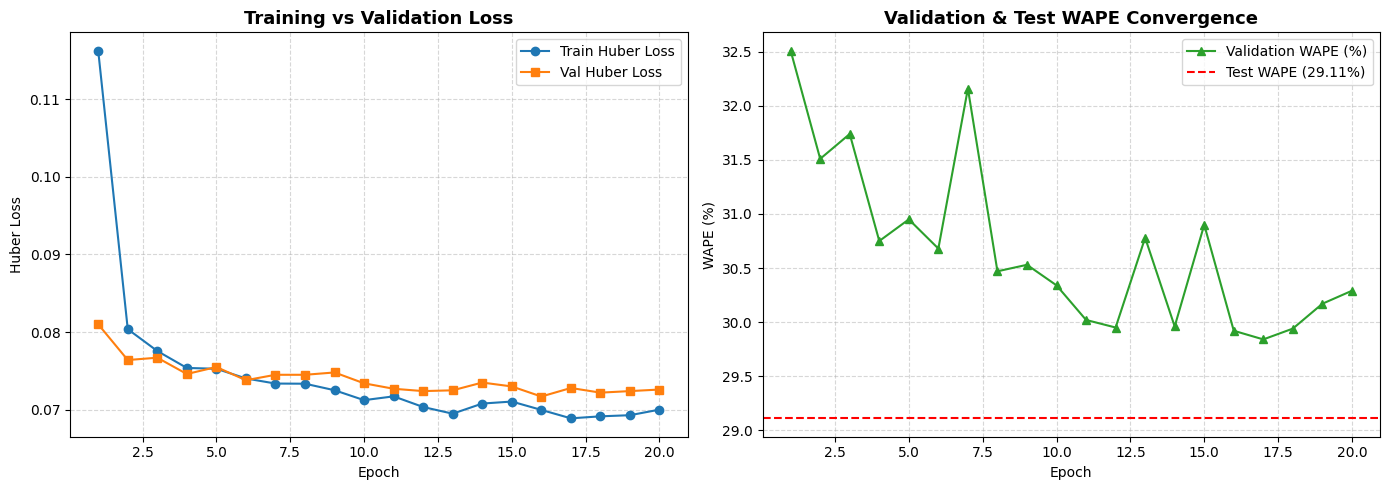

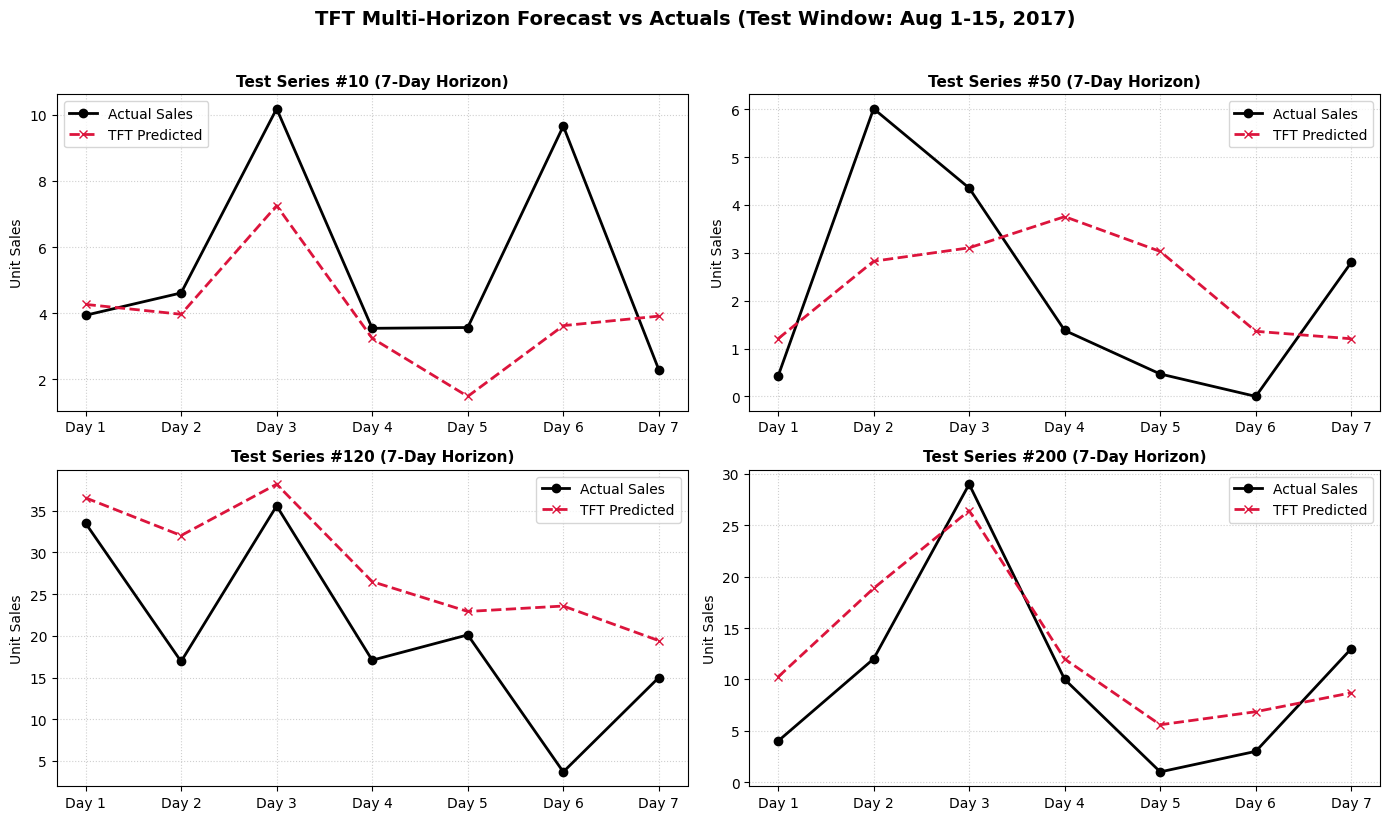

Forecasts exported to: tft_test_forecasts.csv (22,659 forecast rows ready for PSO Optimization)


In [13]:
# =====================================================================
# CELL 9: R^2 Score Evaluation, Review Plots & Forecast Export
# =====================================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score

# 1. Generate Full Test Set Predictions
champion_model.eval()
all_test_preds = []
all_test_actuals = []

with torch.no_grad():
    for batch in test_loader:
        past_x   = batch["past_x"].to(DEVICE)
        future_x = batch["future_x"].to(DEVICE)
        static_x = batch["static_x"].to(DEVICE)

        preds = champion_model(past_x, future_x, static_x)
        all_test_preds.append(preds.cpu())
        all_test_actuals.append(batch["y_raw"])

test_preds_scaled = torch.cat(all_test_preds, dim=0).numpy()
test_actuals_raw  = torch.cat(all_test_actuals, dim=0).numpy()
test_preds_raw    = inverse_scale(test_preds_scaled, target_scaler)

# 2. Compute R^2 Metrics (Overall and Day-by-Day)
overall_r2 = r2_score(test_actuals_raw.ravel(), test_preds_raw.ravel())

day_r2_scores = []
for day in range(7):
    r2_day = r2_score(test_actuals_raw[:, day], test_preds_raw[:, day])
    day_r2_scores.append(r2_day)

print("=" * 55)
print("COMPREHENSIVE TEST SET ACCURACY & R^2 METRICS:")
print("=" * 55)
print(f"  - Overall R^2 Score:     {overall_r2:.4f}  ({overall_r2 * 100:.2f}% variance explained)")
print(f"  - Test WAPE:             {test_metrics['WAPE (%)']}%")
print(f"  - Test MAE:              {test_metrics['MAE']}")
print(f"  - Test RMSE:             {test_metrics['RMSE']}")
print("\nDay-by-Day R^2 Across 7-Day Forecast Horizon:")
for d, r2 in enumerate(day_r2_scores, 1):
    print(f"  - Day {d} (t+{d}): R^2 = {r2:.4f}")
print("=" * 55)

# 3. Plot 1: Training Convergence (Loss & WAPE over Epochs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history["train_loss"]) + 1)
ax1.plot(epochs_range, history["train_loss"], label="Train Huber Loss", marker="o", color="#1f77b4")
ax1.plot(epochs_range, history["val_loss"], label="Val Huber Loss", marker="s", color="#ff7f0e")
ax1.set_title("Training vs Validation Loss", fontsize=13, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Huber Loss")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

ax2.plot(epochs_range, history["val_wape"], label="Validation WAPE (%)", marker="^", color="#2ca02c")
ax2.axhline(y=test_metrics["WAPE (%)"], color="r", linestyle="--", label=f"Test WAPE ({test_metrics['WAPE (%)']}%)")
ax2.set_title("Validation & Test WAPE Convergence", fontsize=13, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("WAPE (%)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

# 4. Plot 2: Actual vs Predicted Demand for Sample Store-Item Pairs
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()
sample_indices = [10, 50, 120, 200]  # Representative test sequences

for i, idx in enumerate(sample_indices):
    act = test_actuals_raw[idx]
    prd = test_preds_raw[idx]
    days = [f"Day {d}" for d in range(1, 8)]
    
    axes[i].plot(days, act, label="Actual Sales", marker="o", color="black", linewidth=2)
    axes[i].plot(days, prd, label="TFT Predicted", marker="x", color="crimson", linewidth=2, linestyle="--")
    axes[i].set_title(f"Test Series #{idx} (7-Day Horizon)", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Unit Sales")
    axes[i].grid(True, linestyle=":", alpha=0.6)
    axes[i].legend()

plt.suptitle("TFT Multi-Horizon Forecast vs Actuals (Test Window: Aug 1-15, 2017)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 5. Export Predictions to CSV for Step 12 (PSO Inventory Optimization)
export_rows = []
for seq_idx in range(len(test_actuals_raw)):
    for day in range(7):
        export_rows.append({
            "sequence_id": seq_idx,
            "forecast_day": day + 1,
            "actual_sales": test_actuals_raw[seq_idx, day],
            "predicted_sales": round(float(test_preds_raw[seq_idx, day]), 2)
        })

df_export = pd.DataFrame(export_rows)
df_export.to_csv("tft_test_forecasts.csv", index=False)
print(f"Forecasts exported to: tft_test_forecasts.csv ({len(df_export):,} forecast rows ready for PSO Optimization)")